In [1]:
import torch
import matplotlib.pyplot as plt
from sklearn.manifold import MDS
from latentlib.manifold import get_euclidean_distances

In [2]:
np_dir = "dimenet10conf_embeddings"

In [3]:
preds = torch.load(f"{np_dir}/u_preds_cas.pt")

In [4]:
layers = ["emb_unique_cas.pt"] + [f"output{i}_unique_cas.pt" for i in range(5)] + [
    "u_mlp_input_cas.pt", "u_mlp_l1_cas.pt", "u_mlp_l2_cas.pt"]

45 features kept.


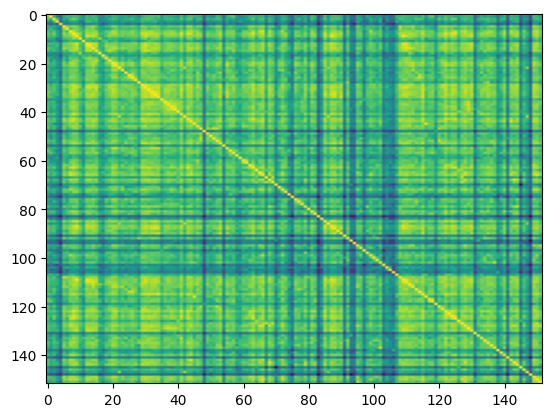

In [214]:
for i, x in enumerate(layers):
    d = torch.load(f"{np_dir}/{x}").squeeze()
    dr = adaptive_zca_whitening(d,1)
    plt.imshow(np.corrcoef(dr), aspect='auto')
    break

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 11476/11476 [00:00<00:00, 110706.19it/s]
/home/frosty/remote/nersc/.venv/lib/python3.11/site-packages/sklearn/manifold/_mds.py:677: FutureWarning: The default value of `n_init` will change from 4 to 1 in 1.9.
  warnings.warn(
100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 11476/11476 [00:00<00:00, 101085.61it/s]
/home/frosty/remote/nersc/.venv/lib/python3.11/site-packages/sklearn/manifold/_mds.py:677: FutureWarning: The default value of `n_init` will change from 4 to 1 in 1.9.
  warnings.warn(
100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 11476/11476 [00:00<00:00, 115670.46it/s]
/home/frosty/remote/nersc/.venv/lib/python3.11/site-packages/sklearn/manifold/_mds.py:677: FutureWarning: Th

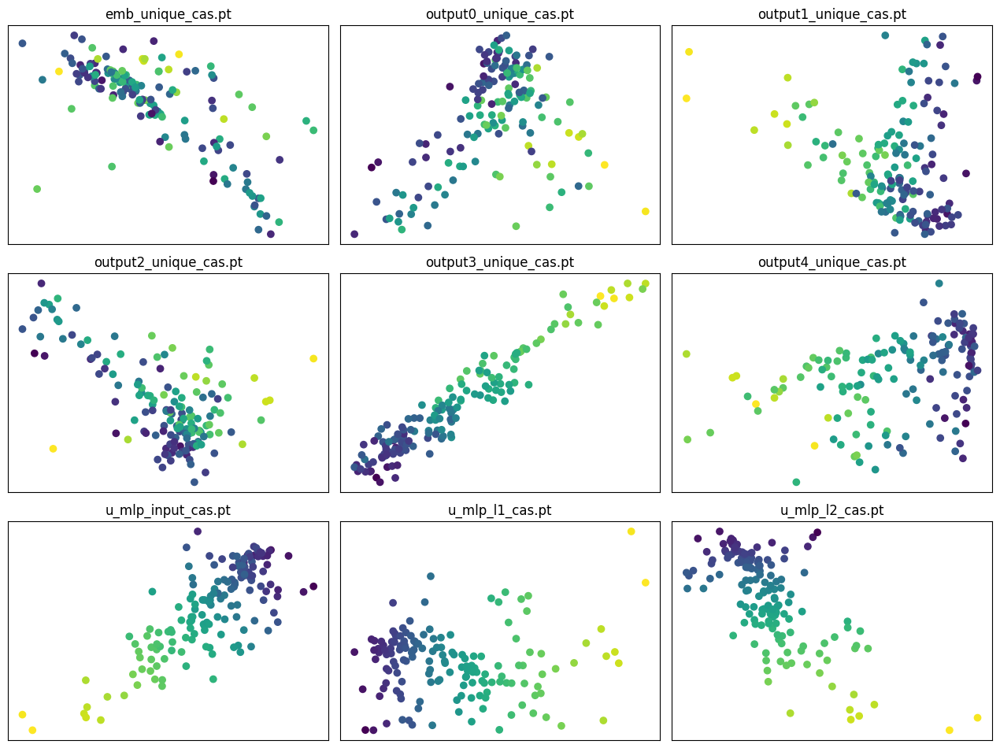

In [8]:
reducer = MDS(n_components=2, dissimilarity='precomputed')
fig, axs = plt.subplots(3,3, figsize=(12.8, 9.6))
af = axs.flatten()

for i, x in enumerate(layers):
    d = torch.load(f"{np_dir}/{x}")
    pos = reducer.fit_transform(get_euclidean_distances(d))
    af[i].scatter(pos[:,0], pos[:,1], c=preds)
    af[i].set_title(x)
    af[i].set_xticks([])
    af[i].set_yticks([])
plt.tight_layout()
plt.show()

100%|████████████████████████████████████████| 69751/69751 [00:00<00:00, 93658.91it/s]
/home/frosty/remote/nersc/.venv/lib/python3.11/site-packages/sklearn/manifold/_mds.py:677: FutureWarning: The default value of `n_init` will change from 4 to 1 in 1.9.
  warnings.warn(
100%|████████████████████████████████████████| 69751/69751 [00:00<00:00, 81063.75it/s]
/home/frosty/remote/nersc/.venv/lib/python3.11/site-packages/sklearn/manifold/_mds.py:677: FutureWarning: The default value of `n_init` will change from 4 to 1 in 1.9.
  warnings.warn(
100%|████████████████████████████████████████| 69751/69751 [00:00<00:00, 79952.63it/s]
/home/frosty/remote/nersc/.venv/lib/python3.11/site-packages/sklearn/manifold/_mds.py:677: FutureWarning: The default value of `n_init` will change from 4 to 1 in 1.9.
  warnings.warn(
100%|████████████████████████████████████████| 69751/69751 [00:00<00:00, 87198.42it/s]
/home/frosty/remote/nersc/.venv/lib/python3.11/site-packages/sklearn/manifold/_mds.py:677: Future

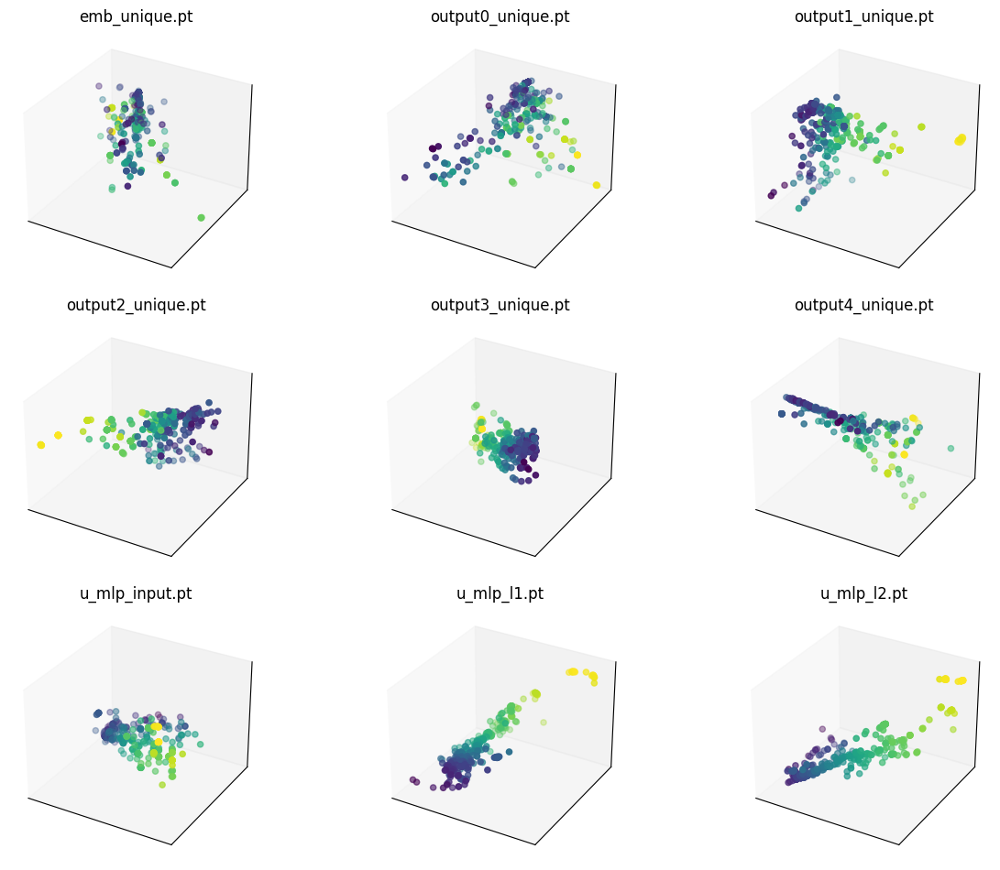

In [35]:
reducer = MDS(n_components=3, dissimilarity='precomputed')
fig, axs = plt.subplots(3,3, figsize=(12.8, 9.6), subplot_kw=dict(projection='3d'))
af = axs.flatten()

for i, x in enumerate(layers):
    d = torch.load(f"{np_dir}/{x}")
    pos = reducer.fit_transform(get_euclidean_distances(d))
    af[i].scatter(pos[:,0], pos[:,1], pos[:,2], c=preds)
    af[i].set_title(x)
    af[i].set_xticks([])
    af[i].set_yticks([])
    af[i].set_zticks([])
plt.tight_layout()
plt.show()

In [14]:
reducer = MDS(n_components=2, dissimilarity='precomputed', random_state=42)
poses = []
for i, x in enumerate(layers):
    d = torch.load(f"{np_dir}/{x}")
    pos = reducer.fit_transform(get_euclidean_distances(d))
    poses.append(pos)

100%|███████████████████████████████████████| 69751/69751 [00:00<00:00, 107704.79it/s]
/home/frosty/remote/nersc/.venv/lib/python3.11/site-packages/sklearn/manifold/_mds.py:677: FutureWarning: The default value of `n_init` will change from 4 to 1 in 1.9.
  warnings.warn(
100%|███████████████████████████████████████| 69751/69751 [00:00<00:00, 113607.45it/s]
/home/frosty/remote/nersc/.venv/lib/python3.11/site-packages/sklearn/manifold/_mds.py:677: FutureWarning: The default value of `n_init` will change from 4 to 1 in 1.9.
  warnings.warn(
100%|███████████████████████████████████████| 69751/69751 [00:00<00:00, 115305.45it/s]
/home/frosty/remote/nersc/.venv/lib/python3.11/site-packages/sklearn/manifold/_mds.py:677: FutureWarning: The default value of `n_init` will change from 4 to 1 in 1.9.
  warnings.warn(
100%|████████████████████████████████████████| 69751/69751 [00:00<00:00, 88502.53it/s]
/home/frosty/remote/nersc/.venv/lib/python3.11/site-packages/sklearn/manifold/_mds.py:677: Future

In [15]:
import numpy as np
min_x = np.min([np.min(x[:,0]) for x in poses])
max_x = np.max([np.max(x[:,0]) for x in poses])
min_y = np.min([np.min(x[:,1]) for x in poses])
max_y = np.max([np.max(x[:,1]) for x in poses])

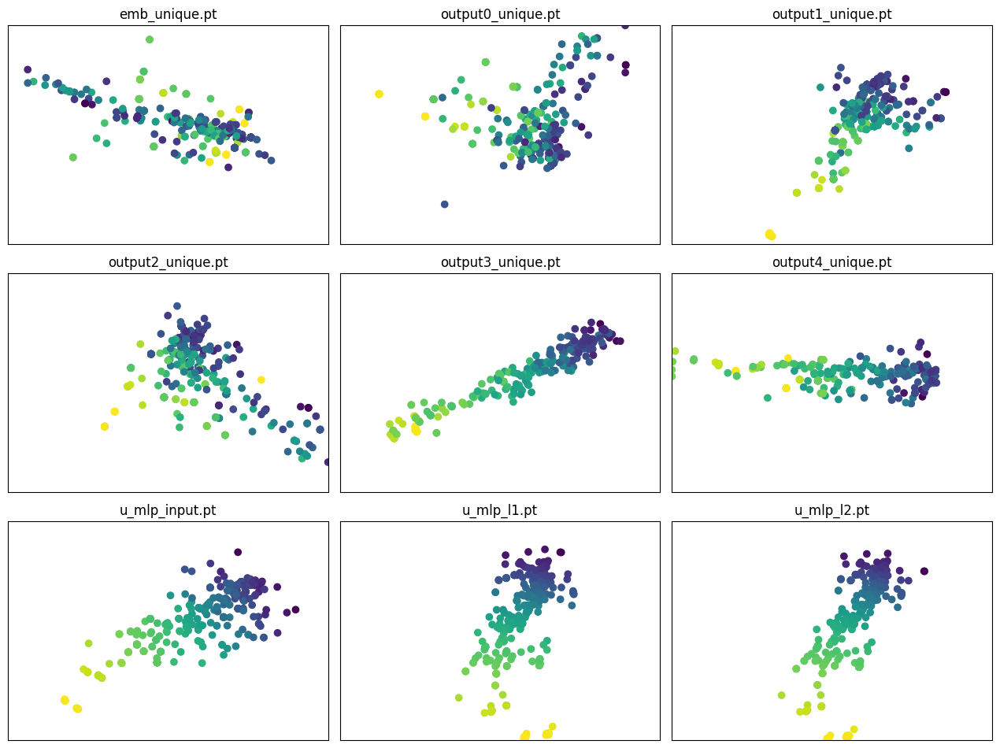

In [16]:
fig, axs = plt.subplots(3,3, figsize=(12.8, 9.6))
af = axs.flatten()

for i, x in enumerate(layers):
    d = torch.load(f"{np_dir}/{x}")
    pos = poses[i]
    af[i].scatter(pos[:,0], pos[:,1], c=preds)
    af[i].set_title(x)
    af[i].set_xticks([])
    af[i].set_yticks([])
    af[i].set_xlim(min_x, max_x)
    af[i].set_ylim(min_y, max_y)
plt.tight_layout()
plt.show()

In [51]:
for i, x in enumerate(layers):
    pos = poses[i]
    np.savetxt(f'{np_dir}/{x}_pos.csv', pos, delimiter=',')

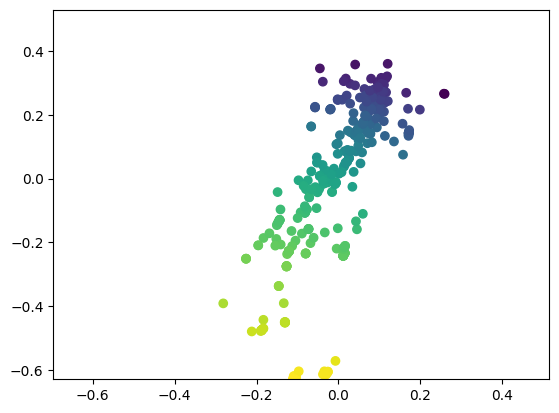

In [83]:
%matplotlib inline
from IPython.display import HTML
import matplotlib.animation as animation
fig, ax = plt.subplots()
plt.ioff()
points = ax.scatter(poses[0][:,0], poses[0][:,1], c=preds)
ax.set_xlim(min_x, max_x)
ax.set_ylim(min_y, max_y)
af[i].set_xticks([])
af[i].set_yticks([])

def update(frame):
    points.set_offsets(poses[frame])
    return points, 
    
a = animation.FuncAnimation(fig=fig, func=update, frames=9, interval=100)
HTML(a.to_html5_video())

# covariance analysis

In [9]:
import numpy as np
for i,x in enumerate(layers):
    d = torch.load(f"{np_dir}/{x}").squeeze().numpy()
    print(np.linalg.det(np.cov(d)))

-0.0
0.0
0.0
0.0
0.0
0.0
0.0
-0.0
-0.0


In [38]:
def reduced_zca_whitening_matrix_adaptive(X, threshold, epsilon = 1e-5):
    sigma = np.cov(X, rowvar=False) # [M x M]
    # Singular Value Decomposition. X = U * np.diag(S) * V
    U,S,V = np.linalg.svd(sigma)
    
    k = 0 
    for v in S:
        if v > threshold:
            k += 1
    print(k)
    top_U = U[:,:k]
    top_S = S[:k]

    red_zca = np.dot(np.diag(1.0/np.sqrt(top_S + epsilon)), top_U.T)
    return red_zca.T

In [15]:
d0 = torch.load(f"{np_dir}/{layers[0]}")

In [16]:
r_zca = reduced_zca_whitening_matrix_adaptive(d0, 1)
decorr_d = d0 @ r_zca

45


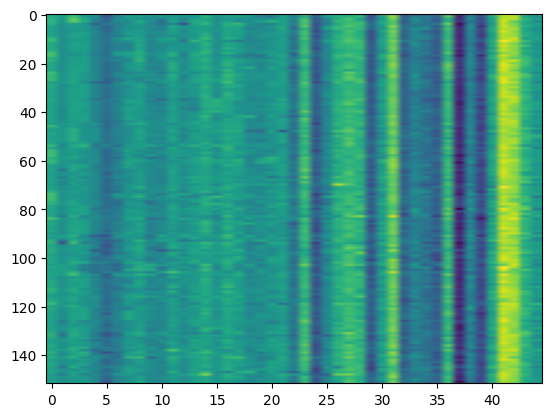

In [17]:
plt.imshow(decorr_d, aspect='auto')

In [43]:
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
gmm = GaussianMixture(n_components=20, covariance_type='full', random_state=42,
max_iter=100)

64189.7876194657 -1183.4853607099503
2.1940724381670562e-243


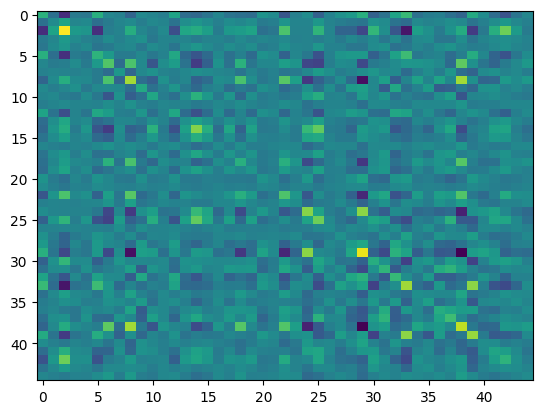

In [44]:
gmm.fit(decorr_d)
print(gmm.bic(decorr_d), gmm.aic(decorr_d))
lbls = gmm.predict(decorr_d)
for x in gmm.covariances_:
    plt.imshow(x, aspect='auto')
    print(np.linalg.det(x))
    break

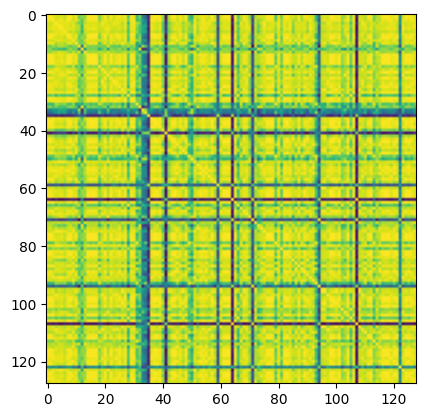

In [32]:
plt.imshow(pd.DataFrame(d0).corr())

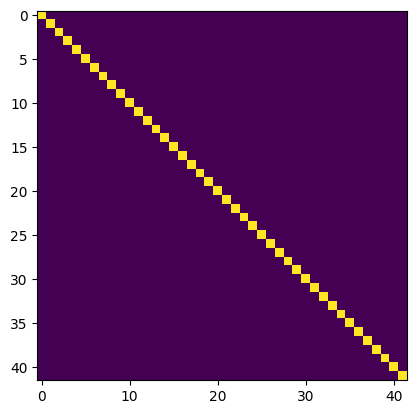

In [31]:
import pandas as pd
plt.imshow(pd.DataFrame(decorr_d).corr())

In [12]:
reducer = MDS(n_components=2, dissimilarity='precomputed', random_state=42)
poses = []
for i, x in enumerate(layers):
    d = torch.load(f"{np_dir}/{x}").squeeze()
    r_zca = reduced_zca_whitening_matrix_adaptive(d, 1)
    dd = d @ r_zca
    pos = reducer.fit_transform(get_euclidean_distances(dd))
    poses.append(pos)

45


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 11476/11476 [00:00<00:00, 66466.30it/s]
/home/frosty/remote/nersc/.venv/lib/python3.11/site-packages/sklearn/manifold/_mds.py:677: FutureWarning: The default value of `n_init` will change from 4 to 1 in 1.9.
  warnings.warn(


4


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 11476/11476 [00:00<00:00, 65696.56it/s]
/home/frosty/remote/nersc/.venv/lib/python3.11/site-packages/sklearn/manifold/_mds.py:677: FutureWarning: The default value of `n_init` will change from 4 to 1 in 1.9.
  warnings.warn(


6


...

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 11476/11476 [00:00<00:00, 69470.82it/s]
/home/frosty/remote/nersc/.venv/lib/python3.11/site-packages/sklearn/manifold/_mds.py:677: FutureWarning: The default value of `n_init` will change from 4 to 1 in 1.9.
  warnings.warn(


4


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 11476/11476 [00:00<00:00, 66463.27it/s]
/home/frosty/remote/nersc/.venv/lib/python3.11/site-packages/sklearn/manifold/_mds.py:677: FutureWarning: The default value of `n_init` will change from 4 to 1 in 1.9.
  warnings.warn(


2


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 11476/11476 [00:00<00:00, 69758.17it/s]
/home/frosty/remote/nersc/.venv/lib/python3.11/site-packages/sklearn/manifold/_mds.py:677: FutureWarning: The default value of `n_init` will change from 4 to 1 in 1.9.
  warnings.warn(


In [13]:
import numpy as np
min_x = np.min([np.min(x[:,0]) for x in poses])
max_x = np.max([np.max(x[:,0]) for x in poses])
min_y = np.min([np.min(x[:,1]) for x in poses])
max_y = np.max([np.max(x[:,1]) for x in poses])

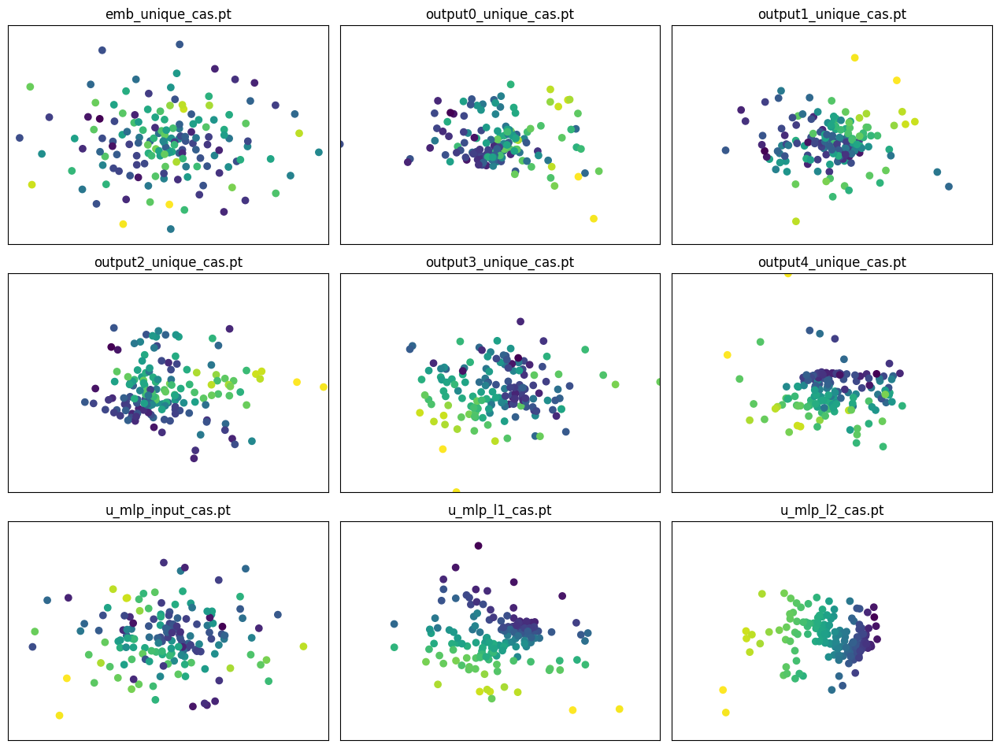

In [14]:
fig, axs = plt.subplots(3,3, figsize=(12.8, 9.6))
af = axs.flatten()

for i, x in enumerate(layers):
    d = torch.load(f"{np_dir}/{x}")
    pos = poses[i]
    af[i].scatter(pos[:,0], pos[:,1], c=preds)
    af[i].set_title(x)
    af[i].set_xticks([])
    af[i].set_yticks([])
    af[i].set_xlim(min_x, max_x)
    af[i].set_ylim(min_y, max_y)
plt.tight_layout()
plt.show()

# spectral clustering

In [5]:
from sklearn.cluster import OPTICS, KMeans, SpectralClustering
from stats import adaptive_zca_whitening

In [6]:
reducer = MDS(n_components=2, dissimilarity='precomputed', random_state=42)
poses = []
labels = []
for i, x in enumerate(layers):
    d = torch.load(f"{np_dir}/{x}").squeeze()
    dd = adaptive_zca_whitening(d, 1)
    labels.append(SpectralClustering(n_clusters=8).fit_predict(dd.numpy()))
    pos = reducer.fit_transform(get_euclidean_distances(dd))
    poses.append(pos)

45 features kept.


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 11476/11476 [00:00<00:00, 91275.27it/s]
/home/frosty/remote/nersc/.venv/lib/python3.11/site-packages/sklearn/manifold/_mds.py:677: FutureWarning: The default value of `n_init` will change from 4 to 1 in 1.9.
  warnings.warn(


4 features kept.


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 11476/11476 [00:00<00:00, 79093.21it/s]
/home/frosty/remote/nersc/.venv/lib/python3.11/site-packages/sklearn/manifold/_mds.py:677: FutureWarning: The default value of `n_init` will change from 4 to 1 in 1.9.
  warnings.warn(


6 features kept.


...

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 11476/11476 [00:00<00:00, 83852.47it/s]
/home/frosty/remote/nersc/.venv/lib/python3.11/site-packages/sklearn/manifold/_mds.py:677: FutureWarning: The default value of `n_init` will change from 4 to 1 in 1.9.
  warnings.warn(


4 features kept.


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 11476/11476 [00:00<00:00, 73391.08it/s]
/home/frosty/remote/nersc/.venv/lib/python3.11/site-packages/sklearn/manifold/_mds.py:677: FutureWarning: The default value of `n_init` will change from 4 to 1 in 1.9.
  warnings.warn(


2 features kept.


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 11476/11476 [00:00<00:00, 71701.99it/s]
/home/frosty/remote/nersc/.venv/lib/python3.11/site-packages/sklearn/manifold/_mds.py:677: FutureWarning: The default value of `n_init` will change from 4 to 1 in 1.9.
  warnings.warn(


In [7]:
import numpy as np
min_x = np.min([np.min(x[:,0]) for x in poses])
max_x = np.max([np.max(x[:,0]) for x in poses])
min_y = np.min([np.min(x[:,1]) for x in poses])
max_y = np.max([np.max(x[:,1]) for x in poses])

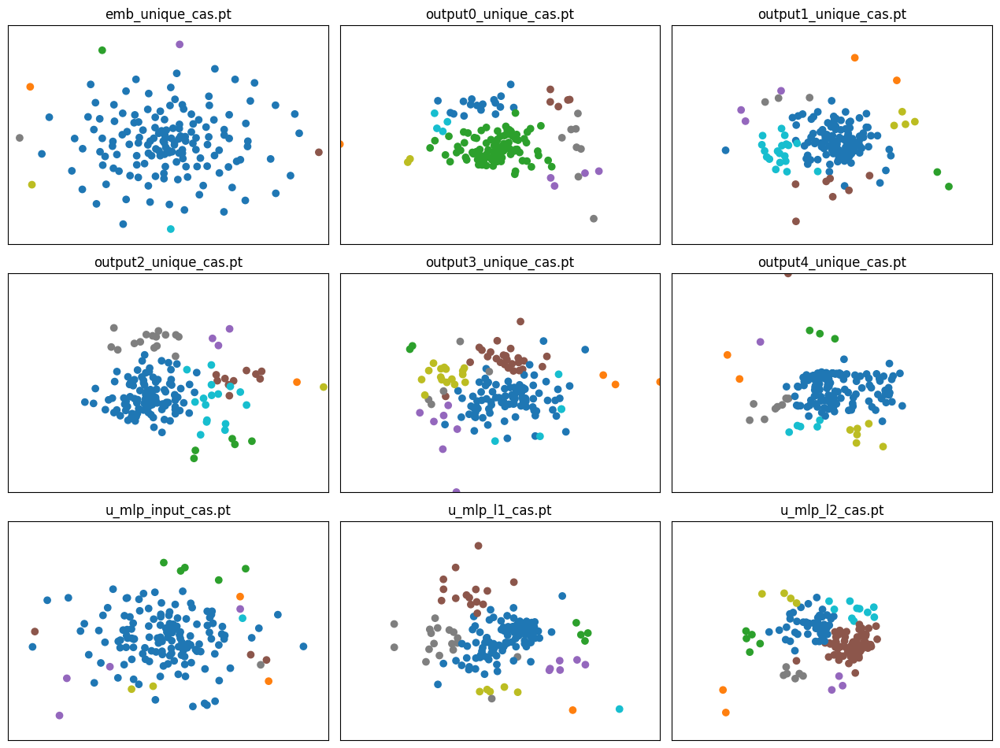

In [8]:
fig, axs = plt.subplots(3,3, figsize=(12.8, 9.6))
af = axs.flatten()

for i, x in enumerate(layers):
    pos = poses[i]
    af[i].scatter(pos[:,0], pos[:,1], c=labels[i], cmap='tab10')
    af[i].set_title(x)
    af[i].set_xticks([])
    af[i].set_yticks([])
    af[i].set_xlim(min_x, max_x)
    af[i].set_ylim(min_y, max_y)
plt.tight_layout()
plt.show()

In [53]:
import pandas as pd
import matplotlib.pyplot as plt
from pandas.plotting import parallel_coordinates

In [54]:
flabels = np.stack([l.flatten() for l in labels]).T
layer_lbls = [x.split('.')[0] for x in layers]

In [55]:
df = pd.DataFrame(flabels, columns=layer_lbls)
df['preds'] = preds

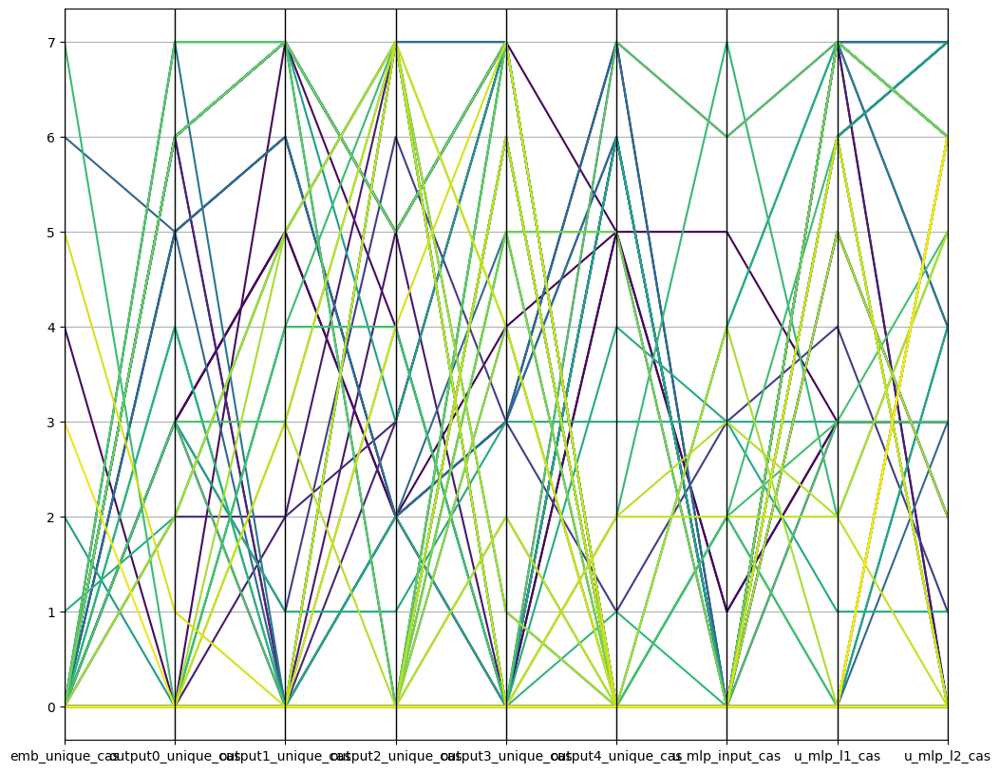

In [56]:
fig, ax = plt.subplots(figsize=(12, 10))
parallel_coordinates(df, 'preds', colormap='viridis', ax=ax)
plt.gca().legend_.remove()

# SOM + SMILES

In [9]:
from model_setup import dimenet10conf
model, data, smiles = dimenet10conf()

Using args.json: /home/frosty/remote/nersc/Libra-ML-Modeling/model-training/butene/dimenet-10conf/models/split_000/seed_0/lightning_logs/version_0/args.json
Checkpoint path: /home/frosty/remote/nersc/Libra-ML-Modeling/model-training/butene/dimenet-10conf/models/split_000/seed_0/lightning_logs/version_0/checkpoints/epoch=16-val_loss=0.324.ckpt
Literature JSON path: /home/frosty/remote/nersc/Libra-ML-Modeling/model-training/butene/dimenet-10conf/data/jsons/split_0.json
Loading checkpoint: /home/frosty/remote/nersc/Libra-ML-Modeling/model-training/butene/dimenet-10conf/models/split_000/seed_0/lightning_logs/version_0/checkpoints/epoch=16-val_loss=0.324.ckpt (attempt 1/3)
✓ Successfully loaded checkpoint


In [10]:
import pandas as pd
u_smiles = smiles.drop_duplicates(subset=["ligand_1_cas"])
#u_smiles = smiles_df.drop_duplicates(subset=["rxn_id"])
u_smiles

,rxn_id,catalyst_key,ddG,reaction_conditions,source_id,source_type,rxn_type,rxn_name,temperature_deg_c,time_h,...,startingmat_1_smiles,startingmat_1_eq,product_1_cas,product_1_smiles,product_2_cas,product_2_smiles,product_1_product_2_ratio,product_1_product_2_ddg_kcal,procedure,comment
0,HF-2,1879897-29-6_conformer-1,2.410,"[-0.13906904491221478, -0.47536592337405076, -...",https://doi.org/10.1039/C5RA23683E,literature,hydroformylation,Rh catalyzed hydroformylation of linear alpha ...,80,2.0,...,C=CCCCCCC,1,124-19-6,CCCCCCCCC([H])=O,7786-29-0,CC(C([H])=O)CCCCCC,31.0,2.410,NaN,NaN
1,HF-3,1879897-30-9_conformer-1,1.800,"[-0.13906904491221478, -0.47536592337405076, -...",https://doi.org/10.1039/C5RA23683E,literature,hydroformylation,Rh catalyzed hydroformylation of linear alpha ...,80,2.0,...,C=CCCCCCC,1,124-19-6,CCCCCCCCC([H])=O,7786-29-0,CC(C([H])=O)CCCCCC,13.0,1.800,NaN,NaN
4,HF-4,1879897-31-0_conformer-1,1.542,"[-0.13906904491221478, -0.47536592337405076, -...",https://doi.org/10.1039/C5RA23683E,literature,hydroformylation,Rh catalyzed hydroformylation of linear alpha ...,80,2.0,...,C=CCCCCCC,1,124-19-6,CCCCCCCCC([H])=O,7786-29-0,CC(C([H])=O)CCCCCC,9.0,1.542,NaN,NaN
5,HF-5,1879897-32-1_conformer-1,1.542,"[-0.13906904491221478, -0.47536592337405076, -...",https://doi.org/10.1039/C5RA23683E,literature,hydroformylation,Rh catalyzed hydroformylation of linear alpha ...,80,2.0,...,C=CCCCCCC,1,124-19-6,CCCCCCCCC([H])=O,7786-29-0,CC(C([H])=O)CCCCCC,9.0,1.542,NaN,NaN
18,HF-18,1372784-47-8_conformer-1,2.203,"[0.7245583160783812, -0.380733390412232, -0.01...",https://doi.org/10.1039/C5RA23683E,literature,hydroformylation,Rh catalyzed hydroformylation of linear alpha ...,100,NaN,...,C=CCCCCCC,1,124-19-6,CCCCCCCCC([H])=O,7786-29-0,CC(C([H])=O)CCCCCC,19.5,2.203,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3477,HF-147,251941-33-0_conformer-1,1.789,"[-0.13906904491221478, -0.13190332306310124, -...",https://doi.org/10.1021/om990523j,literature,hydroformylation,Rh catalyzed hydroformylation of linear alpha ...,80,NaN,...,C=CCCCCCC,1,124-19-6,CCCCCCCCC([H])=O,7786-29-0,CC(C([H])=O)CCCCCC,12.8,1.789,NaN,NaN
3487,HF-178,220294-06-4_conformer-1,0.587,"[-2.039049239091526, -0.47536592337405076, -1....",https://doi.org/10.1021/ja982117h,literature,hydroformylation,Rh catalyzed hydroformylation of linear alpha ...,36,NaN,...,C=CCCCC,1,111-71-7,CCCCCCC([H])=O,925-54-2,CC(C([H])=O)CCCC,2.6,0.587,NaN,NaN
3497,HF-240,138517-61-0_conformer-1,0.285,"[-0.13906904491221478, -0.38950027328263925, -...",https://doi.org/10.1039/C6CY01990K,literature,hydroformylation,Rh catalyzed hydroformylation of linear alpha ...,80,12.0,...,C=CCCCCCC,1,124-19-6,CCCCCCCCC([H])=O,7786-29-0,CC(C([H])=O)CCCCCC,1.5,0.285,NaN,NaN
3498,HF-254,639477-13-7_conformer-1,3.231,"[-0.13906904491221478, -0.2177689730998163, -0...",https://doi.org/10.1021/om034012f,literature,hydroformylation,Rh catalyzed hydroformylation of linear alpha ...,80,NaN,...,C=CCCCCCC,1,124-19-6,CCCCCCCCC([H])=O,7786-29-0,CC(C([H])=O)CCCCCC,99.9,3.231,NaN,NaN


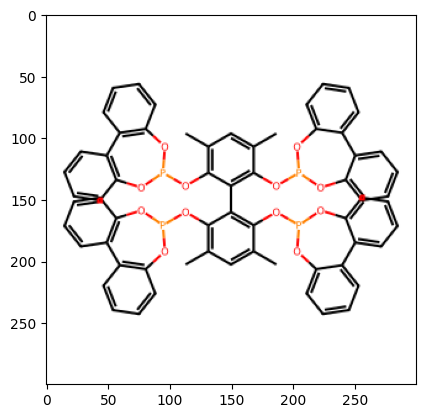

In [21]:
from rdkit import Chem
from rdkit.Chem import Draw
mol = Chem.MolFromSmiles(u_smiles.iloc[0]['ligand_1_smiles'])
from IPython.display import display
plt.imshow(Draw.MolToImage(mol))

In [42]:
import torch
from minisom import MiniSom
import numpy as np
d = torch.load(f"{np_dir}/{layers[-1]}").numpy()9
r_zca = reduced_zca_whitening_matrix_adaptive(d, 1)
dd = d @ r_zca

2


In [55]:
som = MiniSom(10,10, dd.shape[1], sigma=1.5, learning_rate=.5,
              neighborhood_function='gaussian', random_seed=0, topology='rectangular')
som.pca_weights_init(dd)
som.train(dd, 1000, verbose=False)

(0.0, 10.0, 0.0, 10.0)

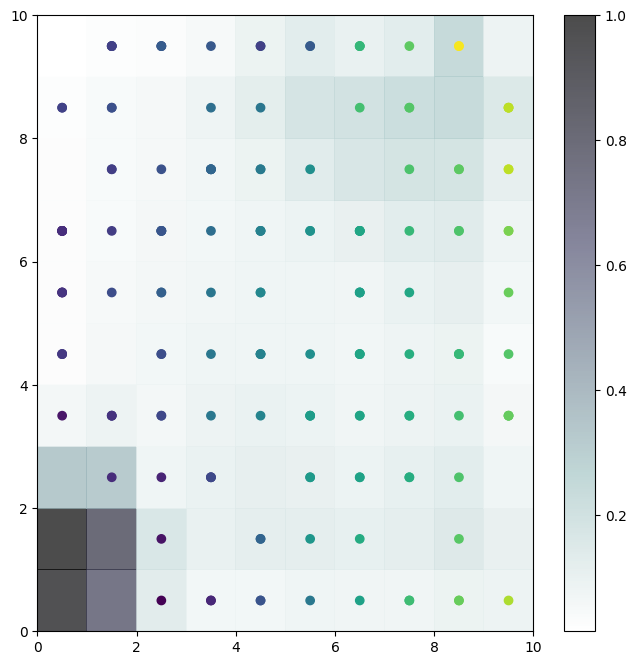

In [76]:
plt.figure(figsize=(8, 8))

plt.pcolor(som.distance_map().T, cmap='bone_r', alpha=.7)  # plotting the distance map as background
plt.colorbar()

w_x, w_y = zip(*[som.winner(x) for x in dd])

plt.scatter(np.array(w_x) + 0.5,np.array(w_y) + 0.5,c=preds)
plt.axis([0, som.get_weights().shape[0], 0,  som.get_weights().shape[1]])

In [57]:
wmap = {}
for i, x in enumerate(dd):
    w = som.winner(x)
    wmap[w] = i

In [64]:
lbls = labels[-1]

In [71]:
colors = cmap_tab10(range(8))
colors

array([[0.12156863, 0.46666667, 0.70588235, 1.        ],
       [1.        , 0.49803922, 0.05490196, 1.        ],
       [0.17254902, 0.62745098, 0.17254902, 1.        ],
       [0.83921569, 0.15294118, 0.15686275, 1.        ],
       [0.58039216, 0.40392157, 0.74117647, 1.        ],
       [0.54901961, 0.3372549 , 0.29411765, 1.        ],
       [0.89019608, 0.46666667, 0.76078431, 1.        ],
       [0.49803922, 0.49803922, 0.49803922, 1.        ]])

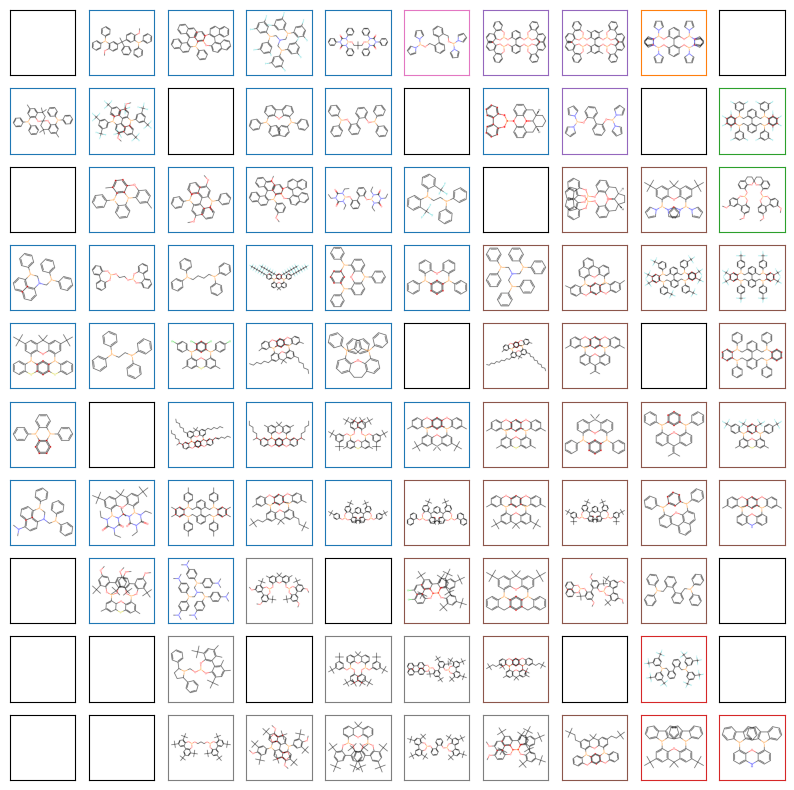

In [82]:
import matplotlib.pyplot as plt
#import matplotlib.colormaps as cm
cmap_tab10 = plt.get_cmap('tab10')
colors = cmap_tab10(range(8))
plt.figure(figsize=(10, 10), facecolor='white')
cnt = 0
for j in reversed(range(10)):  # images mosaic
    for i in range(10):
        ax = plt.subplot(10, 10, cnt+1, frameon=True,  xticks=[],  yticks=[])
        if (i, j) in wmap:
            mol = Chem.MolFromSmiles(u_smiles.iloc[wmap[i,j]]['ligand_1_smiles'])
            c = colors[lbls[wmap[i,j]]]
            ax.spines['top'].set_color(c)
            ax.spines['bottom'].set_color(c)
            ax.spines['left'].set_color(c)
            ax.spines['right'].set_color(c)
            ax.imshow(Draw.MolToImage(mol))
        else:
            ax.imshow(np.zeros((10, 10)),  cmap='Greys')
        cnt = cnt + 1

In [164]:
from rdkit.Chem.Draw import IPythonConsole
from rdkit.Chem import rdDepictor
IPythonConsole.ipython_useSVG = False
IPythonConsole.molSize = 100, 100
rdDepictor.SetPreferCoordGen(True)

In [165]:
u_smiles.columns

Index(['rxn_id', 'catalyst_key', 'ddG', 'reaction_conditions', 'source_id',
       'source_type', 'rxn_type', 'rxn_name', 'temperature_deg_c', 'time_h',
       'atmosphere', 'stirring_shaking', 'scale_mol', 'concentration_mol_l',
       'solvent_1_cas', 'solvent_1_smiles', 'solvent_1_fraction',
       'catalyst_1_name', 'catalyst_1_cas', 'catalyst_1_smiles',
       'catalyst_1_eq', 'ligand_1_name', 'ligand_1_cas', 'ligand_1_smiles',
       'ligand_1_eq', 'reagent_1_cas', 'reagent_1_smiles',
       'reagent_1_pressure_bar', 'reagent_2_cas', 'reagent_2_smiles',
       'reagent_2_pressure_bar', 'startingmat_1_name', 'startingmat_1_cas',
       'startingmat_1_smiles', 'startingmat_1_eq', 'product_1_cas',
       'product_1_smiles', 'product_2_cas', 'product_2_smiles',
       'product_1_product_2_ratio', 'product_1_product_2_ddg_kcal',
       'procedure', 'comment'],
      dtype='object')

In [166]:
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
cmap_tab10 = plt.get_cmap('tab10')(range(8))
tab10_cmap = lambda x: cmap_tab10[x]
cmap_vr = plt.get_cmap('viridis')

norm = Normalize(vmin=torch.min(preds), vmax=torch.max(preds))
vr_cmap = lambda x: cmap_vr(norm(x))

def layer_som(som, d, lbls, u_smiles, title="", cmap=tab10_cmap):
    som.pca_weights_init(d)
    som.train(d, 1000, verbose=False)
    wmap = {}
    for i, x in enumerate(d):
        w = som.winner(x)
        wmap[w] = i
    
    f = plt.figure(figsize=(20, 20), facecolor='white', dpi=200)
    plt.title(title)
    plt.xticks([])#[i for i in range (10)])
    plt.yticks([])#[i for i in range (10)])
    cnt = 0
    for j in reversed(range(10)):  # images mosaic
        for i in range(10):
            ax = plt.subplot(10, 10, cnt+1, frameon=True,  xticks=[],  yticks=[])
            if (i, j) in wmap:
                cas_id = u_smiles.iloc[wmap[i,j]]['ligand_1_cas']
                mol = Chem.MolFromSmiles(u_smiles.iloc[wmap[i,j]]['ligand_1_smiles'])
                c = cmap(lbls[wmap[i,j]])

                locs = ['top', 'bottom', 'left', 'right']
                for x in locs:
                    ax.spines[x].set_color(c)
                    ax.spines[x].set_linewidth(3)
                
                ax.imshow(Draw.MolToImage(mol))
                ax.text(0.5, 0.9, f'({i},{j})', 
                        transform=ax.transAxes, 
                        horizontalalignment='center', 
                        verticalalignment='center', fontsize=16)
                #ax.text(0.5, 0.0, cas_id, 
                #        transform=ax.transAxes, 
                #        horizontalalignment='center', 
                #        verticalalignment='center', fontsize=14)
            else:
                ax.imshow(np.zeros((10, 10)),  cmap='Greys')
            cnt = cnt + 1
    
    plt.tight_layout()

45 features kept.


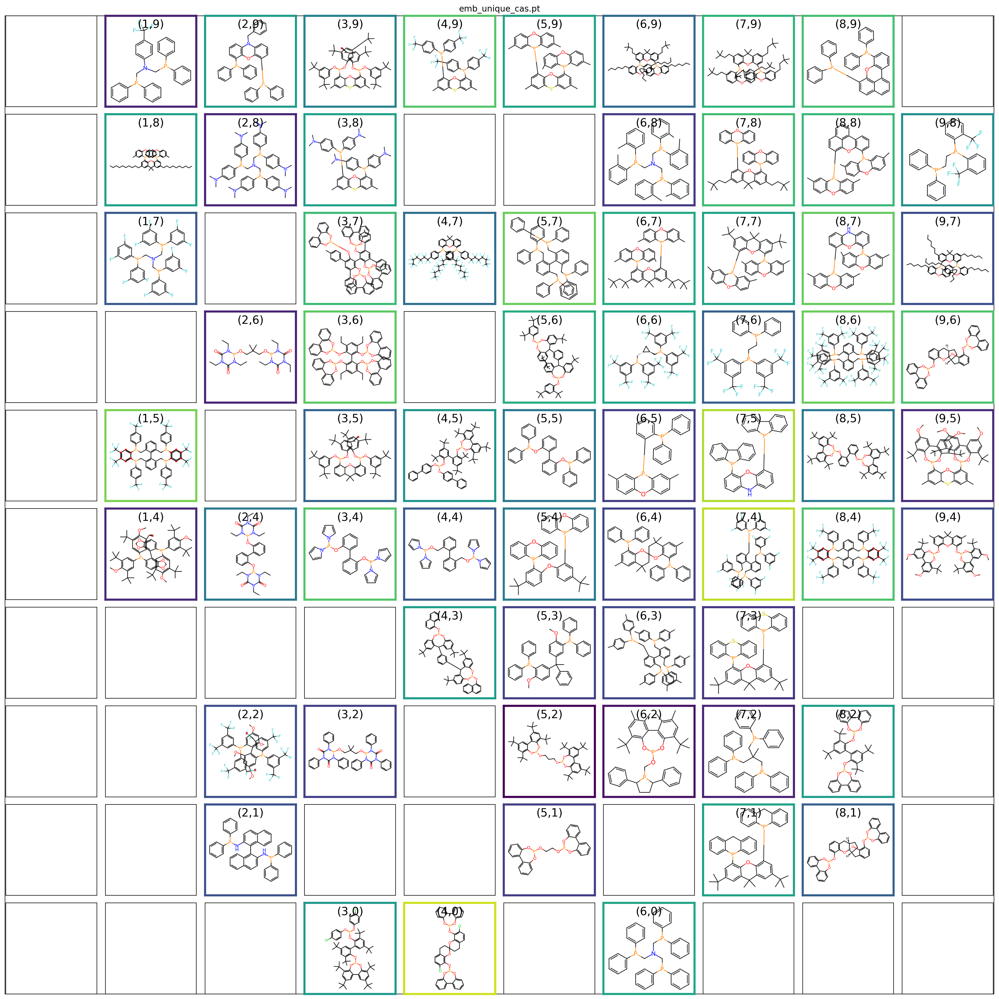

In [167]:
import torch
from minisom import MiniSom
import numpy as np
from stats import adaptive_zca_whitening
from rdkit import Chem
from rdkit.Chem import Draw
ld = torch.load(f"{np_dir}/{layers[0]}").numpy()
decorr = adaptive_zca_whitening(ld, 1)
som = MiniSom(10,10, decorr.shape[1], sigma=1.5, learning_rate=.5,
              neighborhood_function='gaussian', random_seed=0, topology='rectangular')
layer_som(som, decorr, preds, u_smiles, title=layers[0], cmap=vr_cmap)

4 features kept.


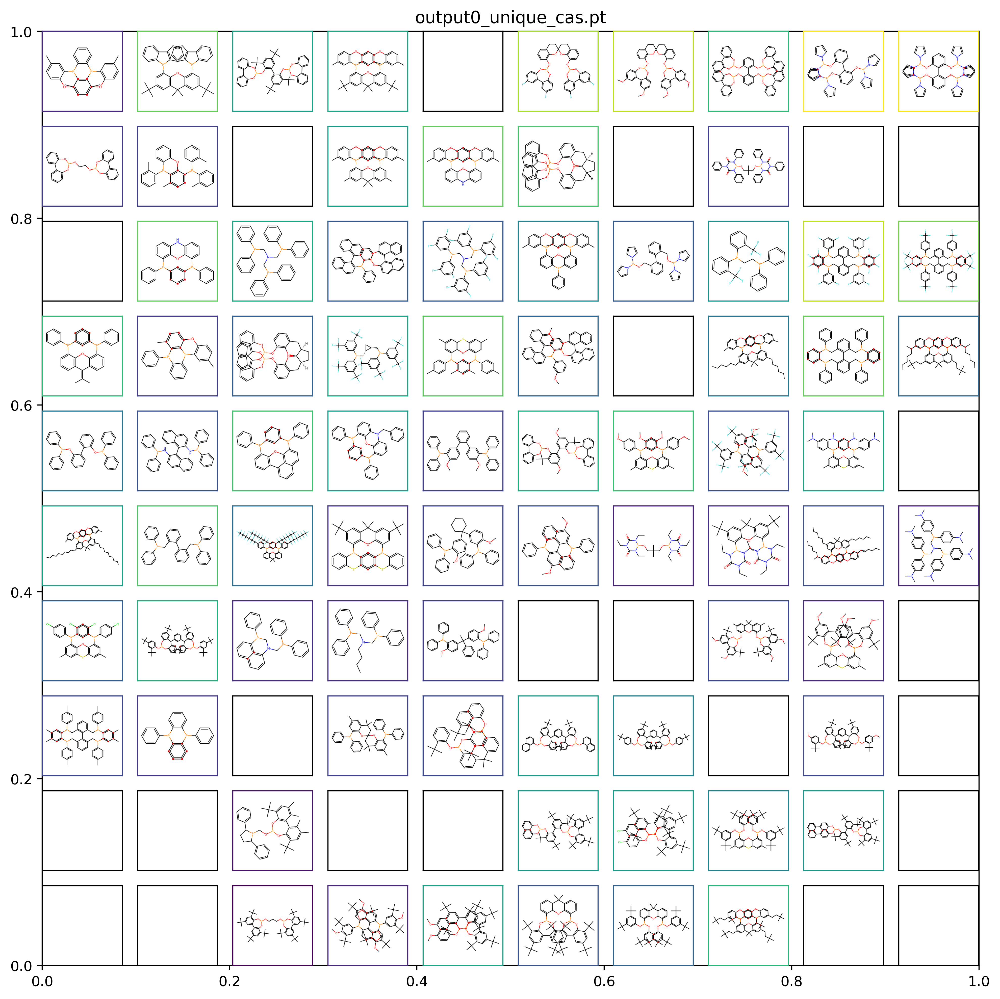

In [51]:
ld = torch.load(f"{np_dir}/{layers[1]}").numpy()
decorr = adaptive_zca_whitening(ld, 1)
som = MiniSom(10,10, decorr.shape[1], sigma=1.5, learning_rate=.5,
              neighborhood_function='gaussian', random_seed=0, topology='rectangular')
layer_som(som, decorr, preds, u_smiles, title=layers[1], cmap=vr_cmap)

6 features kept.


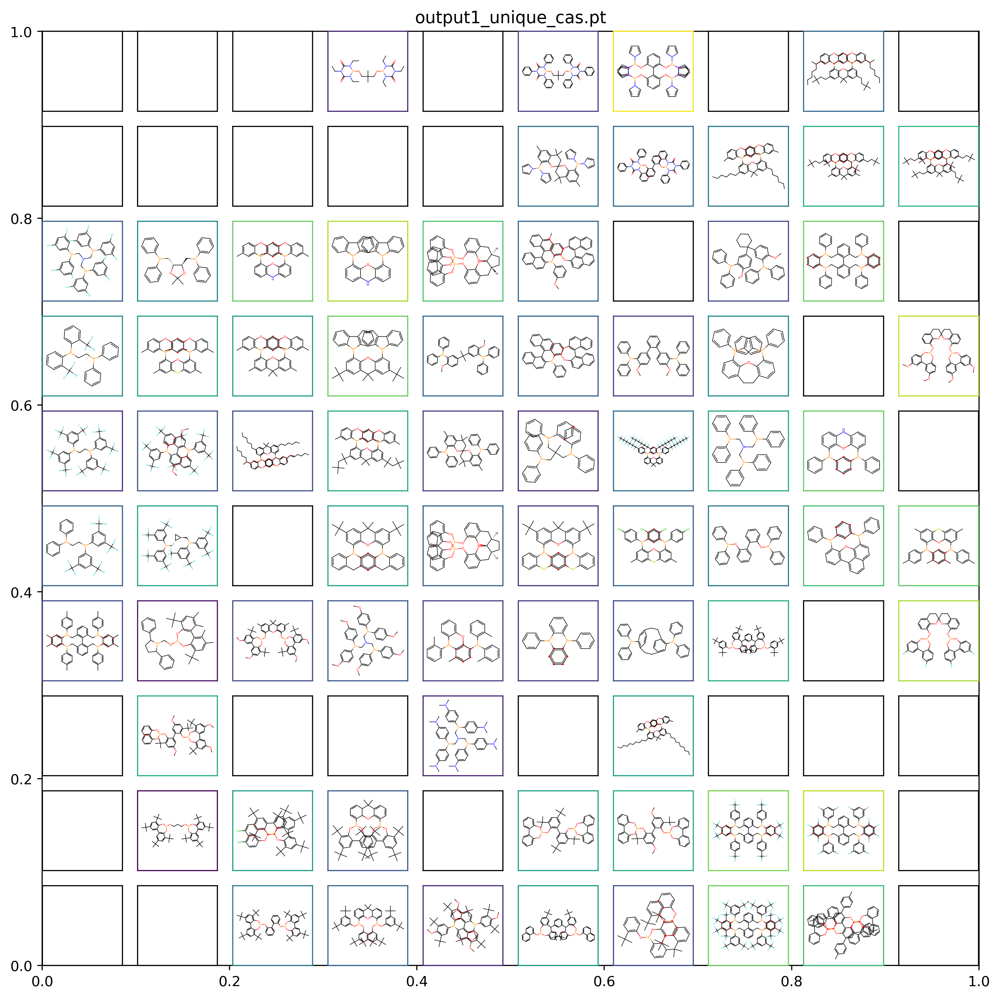

In [52]:
ld = torch.load(f"{np_dir}/{layers[2]}").numpy()
decorr = adaptive_zca_whitening(ld, 1)
som = MiniSom(10,10, decorr.shape[1], sigma=1.5, learning_rate=.5,
              neighborhood_function='gaussian', random_seed=0, topology='rectangular')
layer_som(som, decorr, preds, u_smiles, title=layers[2], cmap=vr_cmap)

3 features kept.


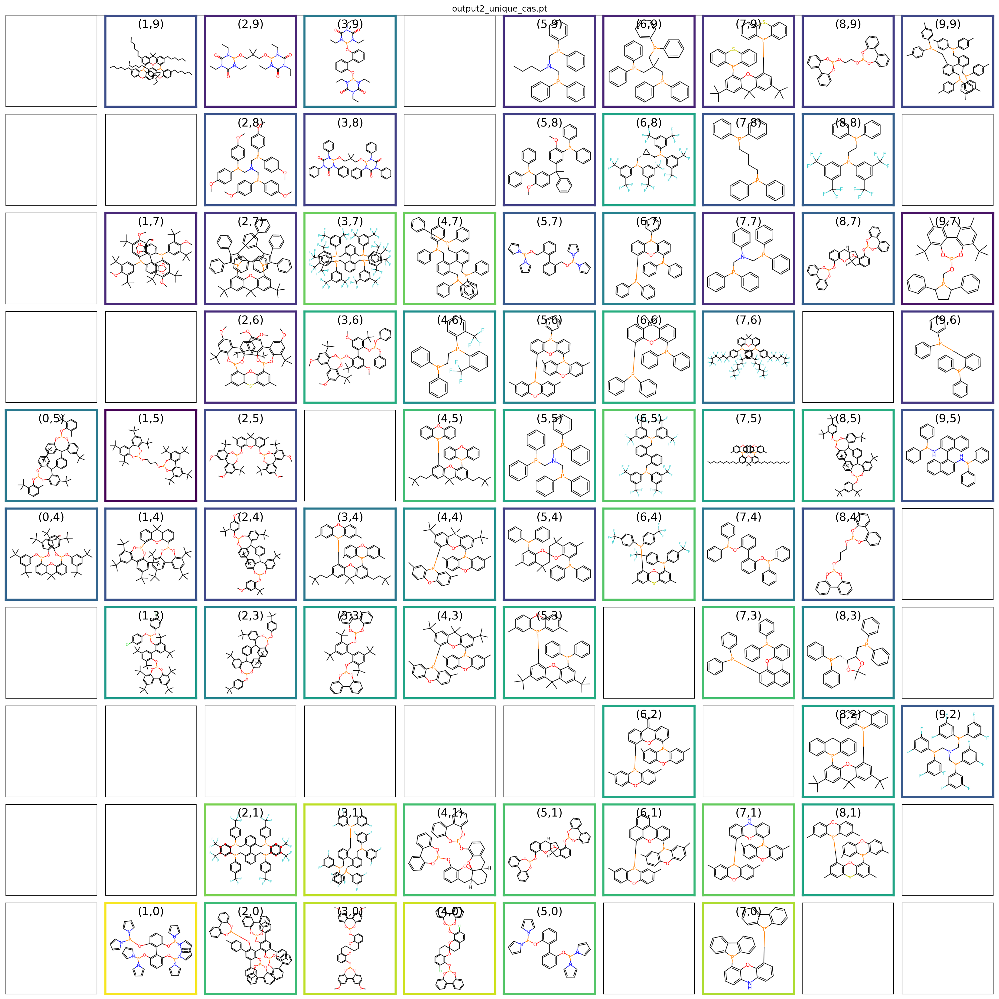

In [168]:
ld = torch.load(f"{np_dir}/{layers[3]}").numpy()
decorr = adaptive_zca_whitening(ld, 1)
som = MiniSom(10,10, decorr.shape[1], sigma=1.5, learning_rate=.5,
              neighborhood_function='gaussian', random_seed=0, topology='rectangular')
layer_som(som, decorr, preds, u_smiles, title=layers[3], cmap=vr_cmap)

6 features kept.


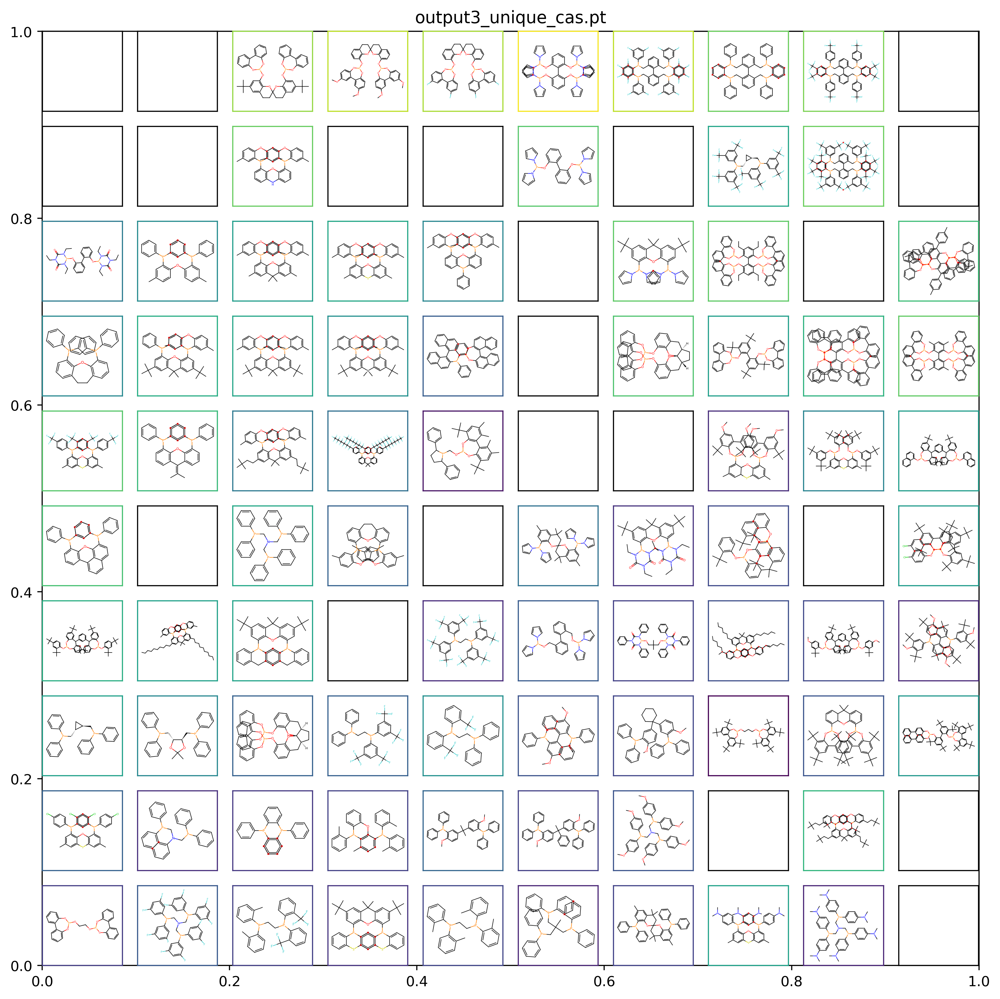

In [54]:
ld = torch.load(f"{np_dir}/{layers[4]}").numpy()
decorr = adaptive_zca_whitening(ld, 1)
som = MiniSom(10,10, decorr.shape[1], sigma=1.5, learning_rate=.5,
              neighborhood_function='gaussian', random_seed=0, topology='rectangular')
layer_som(som, decorr, preds, u_smiles, title=layers[4], cmap=vr_cmap)

4 features kept.


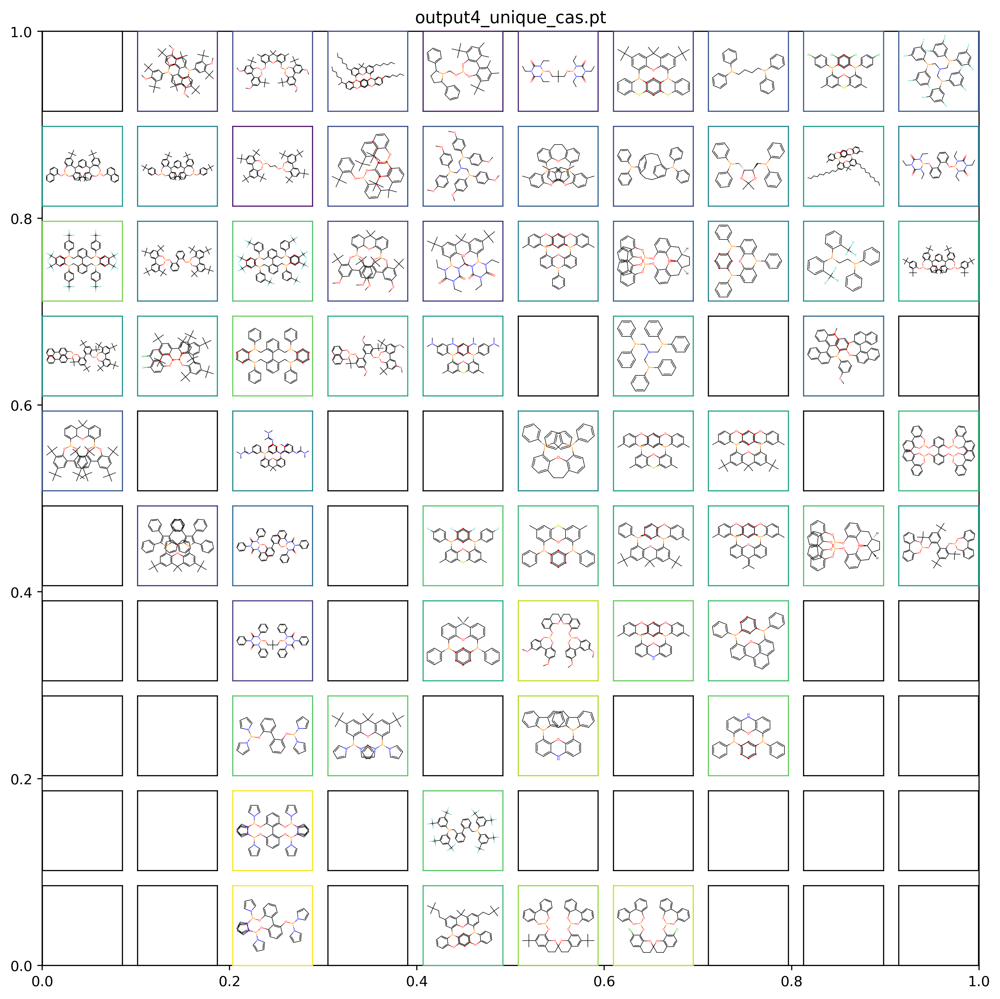

In [55]:
ld = torch.load(f"{np_dir}/{layers[5]}").numpy()
decorr = adaptive_zca_whitening(ld, 1)
som = MiniSom(10,10, decorr.shape[1], sigma=1.5, learning_rate=.5,
              neighborhood_function='gaussian', random_seed=0, topology='rectangular')
layer_som(som, decorr, preds, u_smiles, title=layers[5], cmap=vr_cmap)

16 features kept.


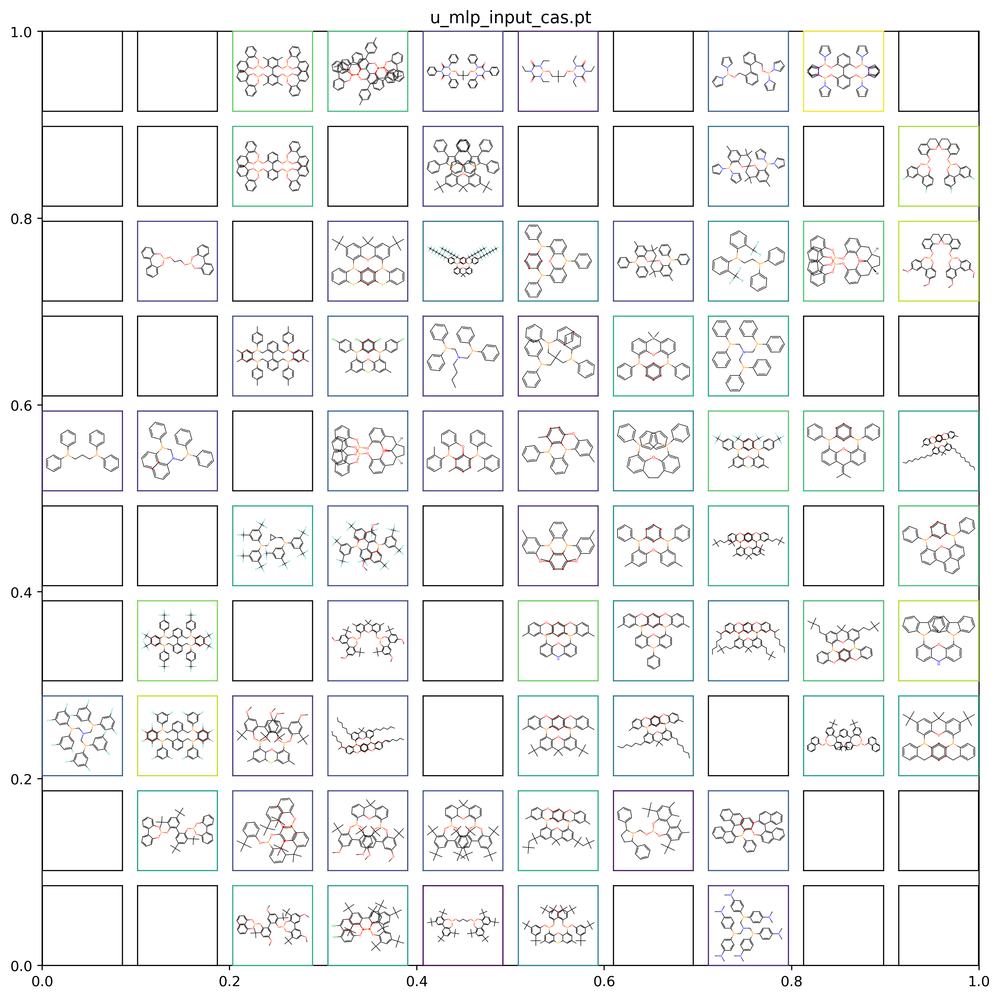

In [56]:
ld = torch.load(f"{np_dir}/{layers[6]}").squeeze().numpy()
decorr = adaptive_zca_whitening(ld, 1)
som = MiniSom(10,10, decorr.shape[1], sigma=1.5, learning_rate=.5,
              neighborhood_function='gaussian', random_seed=0, topology='rectangular')
layer_som(som, decorr, preds, u_smiles, title=layers[6], cmap=vr_cmap)

4 features kept.


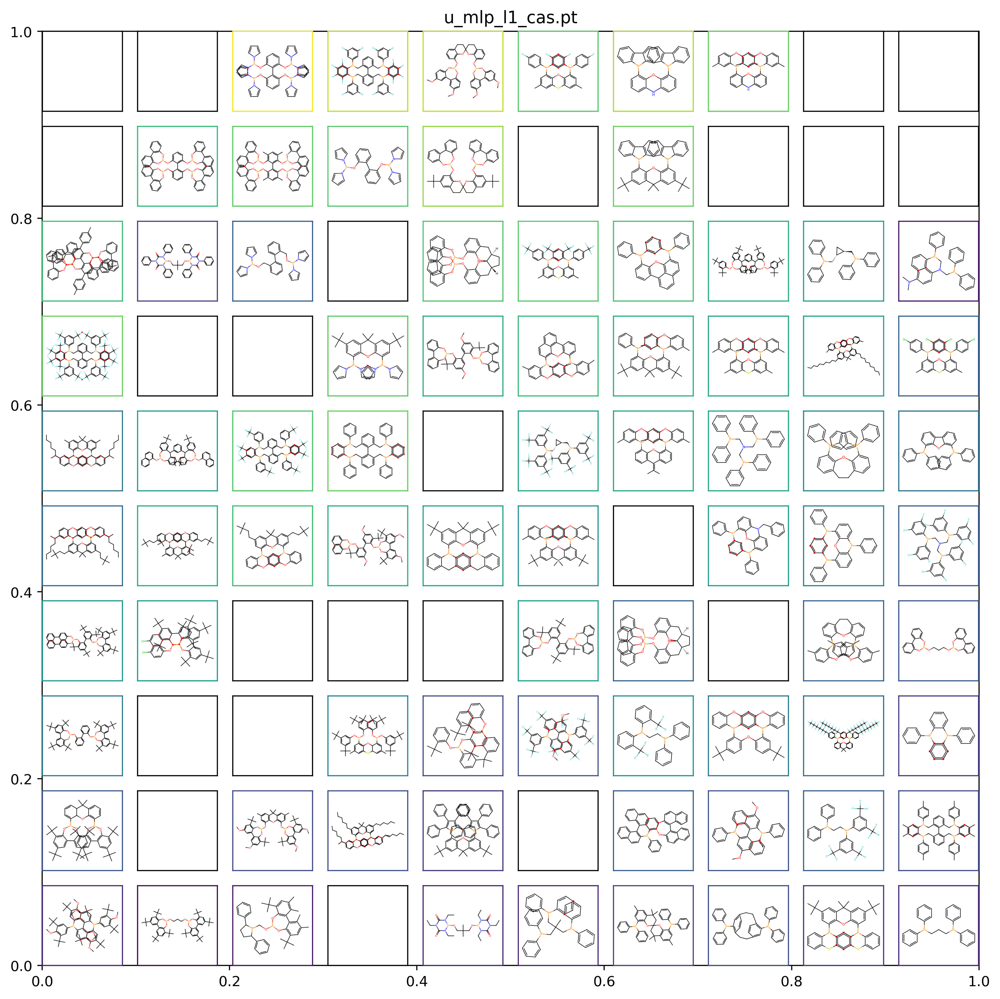

In [57]:
ld = torch.load(f"{np_dir}/{layers[7]}").squeeze().numpy()
decorr = adaptive_zca_whitening(ld, 1)
som = MiniSom(10,10, decorr.shape[1], sigma=1.5, learning_rate=.5,
              neighborhood_function='gaussian', random_seed=0, topology='rectangular')
layer_som(som, decorr, preds, u_smiles, title=layers[7], cmap=vr_cmap)

2 features kept.


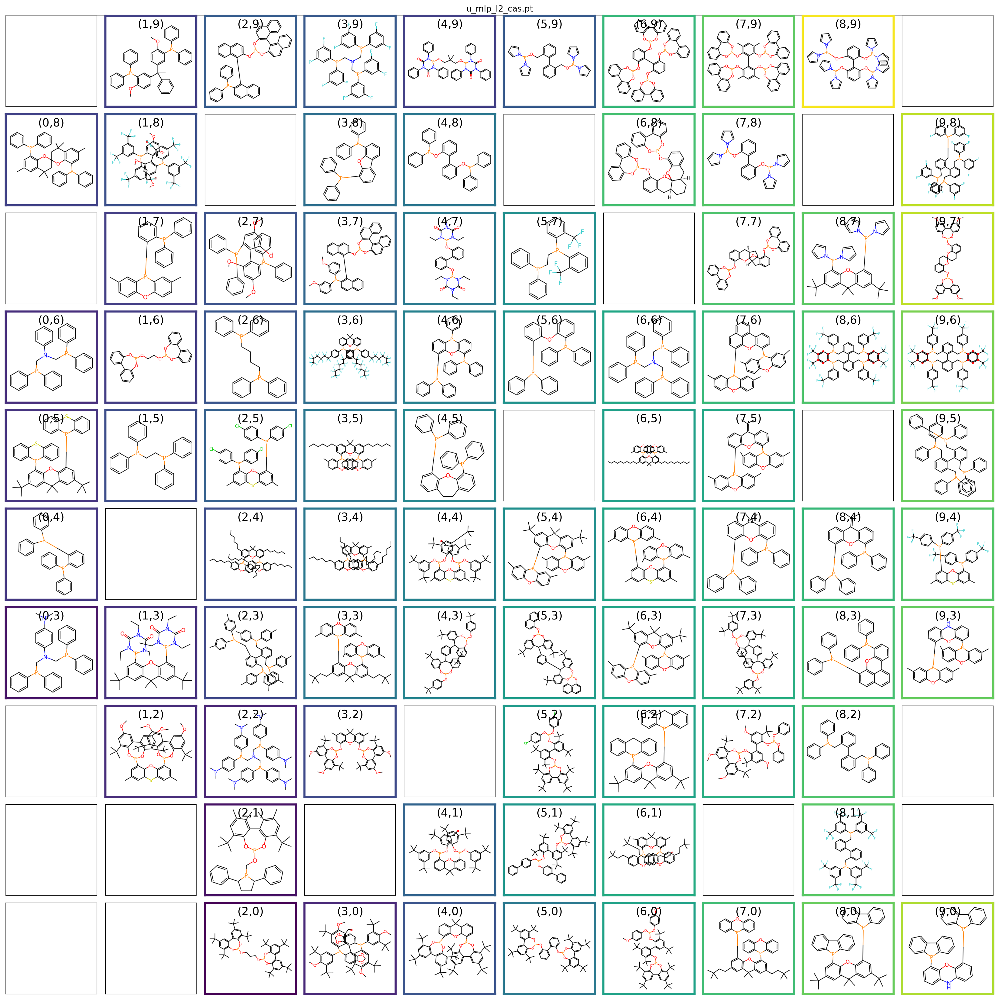

In [169]:
ld = torch.load(f"{np_dir}/{layers[8]}").squeeze().numpy()
decorr = adaptive_zca_whitening(ld, 1)
som = MiniSom(10,10, decorr.shape[1], sigma=1.5, learning_rate=.5,
              neighborhood_function='gaussian', random_seed=0, topology='rectangular')
layer_som(som, decorr, preds, u_smiles, title=layers[8], cmap=vr_cmap)

In [37]:
dir(som)

['Y_HEX_CONV_FACTOR',
 '__class__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__sizeof__',
 '__str__',
 '__subclasshook__',
 '__weakref__',
 '_activate',
 '_activation_distance',
 '_activation_map',
 '_asymptotic_decay',
 '_bubble',
 '_chebyshev_distance',
 '_check_fixed_points',
 '_check_input_len',
 '_check_iteration_number',
 '_cosine_distance',
 '_distance_from_weights',
 '_euclidean_distance',
 '_gaussian',
 '_get_euclidean_coordinates_from_index',
 '_input_len',
 '_inverse_decay_to_one',
 '_inverse_decay_to_zero',
 '_learning_rate',
 '_learning_rate_decay_function',
 '_linear_decay_to_one',
 '_linear_decay_to_zero',
 '_manhattan_distance',
 '_mexican_hat',
 '_neigx',
 '_neigy',
 '_random_generator',
 '_sigma',
 '_si

In [60]:
u_smiles.columns

Index(['rxn_id', 'catalyst_key', 'ddG', 'reaction_conditions', 'source_id',
       'source_type', 'rxn_type', 'rxn_name', 'temperature_deg_c', 'time_h',
       'atmosphere', 'stirring_shaking', 'scale_mol', 'concentration_mol_l',
       'solvent_1_cas', 'solvent_1_smiles', 'solvent_1_fraction',
       'catalyst_1_name', 'catalyst_1_cas', 'catalyst_1_smiles',
       'catalyst_1_eq', 'ligand_1_name', 'ligand_1_cas', 'ligand_1_smiles',
       'ligand_1_eq', 'reagent_1_cas', 'reagent_1_smiles',
       'reagent_1_pressure_bar', 'reagent_2_cas', 'reagent_2_smiles',
       'reagent_2_pressure_bar', 'startingmat_1_name', 'startingmat_1_cas',
       'startingmat_1_smiles', 'startingmat_1_eq', 'product_1_cas',
       'product_1_smiles', 'product_2_cas', 'product_2_smiles',
       'product_1_product_2_ratio', 'product_1_product_2_ddg_kcal',
       'procedure', 'comment'],
      dtype='object')

In [171]:
import numpy as np

# hagrid in Python
# https://link.springer.com/article/10.1007/s12650-022-00854-7

# Assuming `get_scales` and `distance` functions from the previous conversation are available.
# They are included here for a complete, runnable example.
def get_scales(data, target_extent, keep_aspect_ratio=False, round_result=True, x_accessor=lambda d: d[0], y_accessor=lambda d: d[1]):
    """
    Creates scaling functions for a dataset based on source and target extents.
    """
    (X_min, X_max), (Y_min, Y_max) = target_extent
    X_span = X_max - X_min
    Y_span = Y_max - Y_min

    x_values = [x_accessor(d) for d in data]
    y_values = [y_accessor(d) for d in data]
    
    x_min, x_max = min(x_values), max(x_values)
    y_min, y_max = min(y_values), max(y_values)
    x_span = x_max - x_min
    y_span = y_max - y_min

    if keep_aspect_ratio:
        if x_span > y_span:
            offset = (x_span - y_span) / 2
            y_min -= offset
            y_max += offset
        else:
            offset = (y_span - x_span) / 2
            x_min -= offset
            x_max += offset
        x_span = x_max - x_min
        y_span = y_max - y_min

    f = round if round_result else lambda d: d
    x_scale = lambda d: f(((x_accessor(d) - x_min) / x_span) * X_span + X_min)
    y_scale = lambda d: f(((y_accessor(d) - y_min) / y_span) * Y_span + Y_min)
    
    return [x_scale, y_scale]

def distance(a, b):
    """
    Calculates the Euclidean distance between two 2D points.
    """
    return np.hypot(b[0] - a[0], b[1] - a[1])


def rotate(size, px, py, rx, ry):
    """
    Helper function for Hilbert curve encoding/decoding.
    """
    if ry == 0:
        if rx == 1:
            px = size - 1 - px
            py = size - 1 - py
        return py, px
    return px, py

def hilbert_encode(point, size):
    """
    Encodes a 2D point [px, py] to a 1D Hilbert curve index.
    """
    px, py = point
    n = 0
    s = size // 2
    while s > 0:
        rx = (px & s) > 0
        ry = (py & s) > 0
        n += (s * s) * ((3 * rx) ^ ry)
        px, py = rotate(s, px, py, rx, ry)
        s //= 2
    return n

def hilbert_decode(n, size):
    """
    Decodes a 1D Hilbert curve index to a 2D point [px, py].
    """
    t = n
    px, py = 0, 0
    s = 1
    while s < size:
        rx = 1 & (t >> 1)
        ry = 1 & (t ^ rx)
        px, py = rotate(s, px, py, rx, ry)
        px += (s * rx)
        py += (s * ry)
        t >>= 2
        s *= 2
    return [px, py]

def hilbert_collision(P, p, d, i, curveLength, size):
    """
    Handles collisions when multiple data points map to the same Hilbert curve index.
    Finds the nearest unoccupied curve position.
    """
    # A set is more efficient for checking membership (P.has) than a dictionary.
    occupied = set(P.keys())
    
    pl, pr = p + 1, p - 1
    
    while True:
        valid_pl = 0 <= pl < curveLength
        valid_pr = 0 <= pr < curveLength
        
        el = pl not in occupied
        er = pr not in occupied

        if valid_pl and el and (not valid_pr or not er):
            P[pl] = i
            return
        elif valid_pr and er and (not valid_pl or not el):
            P[pr] = i
            return
        elif valid_pl and valid_pr and el and er:
            dl = distance(d, hilbert_decode(pl, size))
            dr = distance(d, hilbert_decode(pr, size))
            P[pl if dl < dr else pr] = i
            return
        
        pl += 1
        pr -= 1


def gridify_hilbert(D, level, keep_aspect_ratio=False):
    """
    Gridifies data points using the Hilbert curve to resolve overlaps.
    
    Args:
        D: A list of data points, where each point is an iterable [x, y].
        level: The level of the Hilbert curve, determining grid size.
        keep_aspect_ratio: If True, maintains the aspect ratio of the data.
    
    Returns:
        A NumPy array of the re-gridded data points.
    """
    size = 2 ** level
    curve_length = size ** 2
    N = len(D)
    
    P = {}  # Using a dictionary for mapping curve index to data index
    Y = np.zeros((N, 2), dtype=int)
    
    scales = get_scales(D, [[0, size - 1], [0, size - 1]], keep_aspect_ratio=keep_aspect_ratio, round_result=True)
    x_scale, y_scale = scales

    for i, d in enumerate(D):
        x = x_scale(d)
        y = y_scale(d)
        
        p = hilbert_encode([x, y], size)
        
        if p in P:
            hilbert_collision(P, p, (x, y), i, curve_length, size)
        else:
            P[p] = i

    for p, i in P.items():
        Y[i] = hilbert_decode(p, size)
    
    return Y

In [176]:
# level = 4 is 256 points, level = 5 is 1024
gridded = gridify_hilbert(poses[-1], 4)

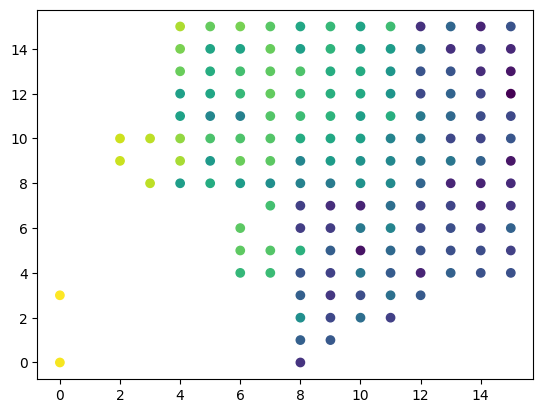

In [177]:
plt.scatter(gridded[:,0], gridded[:,1], c=preds)

In [192]:
def layer_hagrid(poses, level, lbls, u_smiles, figsize=(32,32), title="", cmap=tab10_cmap):
    gridded = gridify_hilbert(poses, level)
    wmap = {}
    for i, x in enumerate(gridded):
        wmap[tuple(x)] = i

    size = 2**level
    
    f = plt.figure(figsize=figsize, facecolor='white', dpi=200)
    plt.title(title, fontsize=18)
    plt.xticks([])#[i for i in range (10)])
    plt.yticks([])#[i for i in range (10)])
    cnt = 0
    for j in reversed(range(size)):  # images mosaic
        for i in range(size):
            ax = plt.subplot(size, size, cnt+1, frameon=True,  xticks=[],  yticks=[])
            if (i, j) in wmap:
                cas_id = u_smiles.iloc[wmap[i,j]]['ligand_1_cas']
                mol = Chem.MolFromSmiles(u_smiles.iloc[wmap[i,j]]['ligand_1_smiles'])
                c = cmap(lbls[wmap[i,j]])

                locs = ['top', 'bottom', 'left', 'right']
                for x in locs:
                    ax.spines[x].set_color(c)
                    ax.spines[x].set_linewidth(3)
                
                ax.imshow(Draw.MolToImage(mol))
                ax.text(0.5, 0.9, f'({i},{j})', 
                        transform=ax.transAxes, 
                        horizontalalignment='center', 
                        verticalalignment='center', fontsize=16)
            else:
                ax.imshow(np.zeros((size, size)),  cmap='Greys')
            cnt = cnt + 1
    
    plt.tight_layout()
    

In [189]:
import os
dname = "gridded_MDS"
os.mkdir(dname)
for i in range(9):
    layer_hagrid(poses[i], 4, preds, u_smiles, title=layers[i], cmap=vr_cmap)
    plt.savefig(f"{dname}/{layers[i].split('.')[0]}.png")
    plt.close()

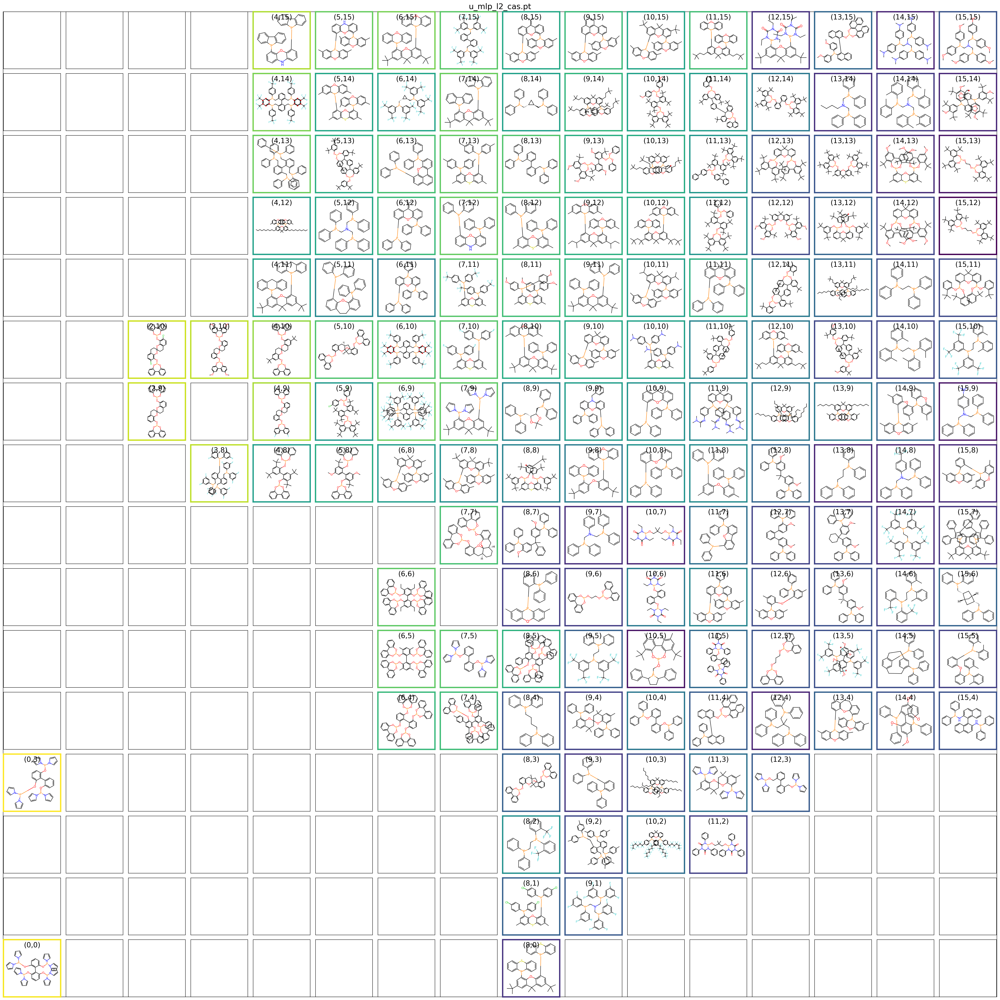

In [193]:
layer_hagrid(poses[-1], 4, preds, u_smiles, title=layers[-1], cmap=vr_cmap)

In [195]:
from vis import chem_grid, sequential_cmap

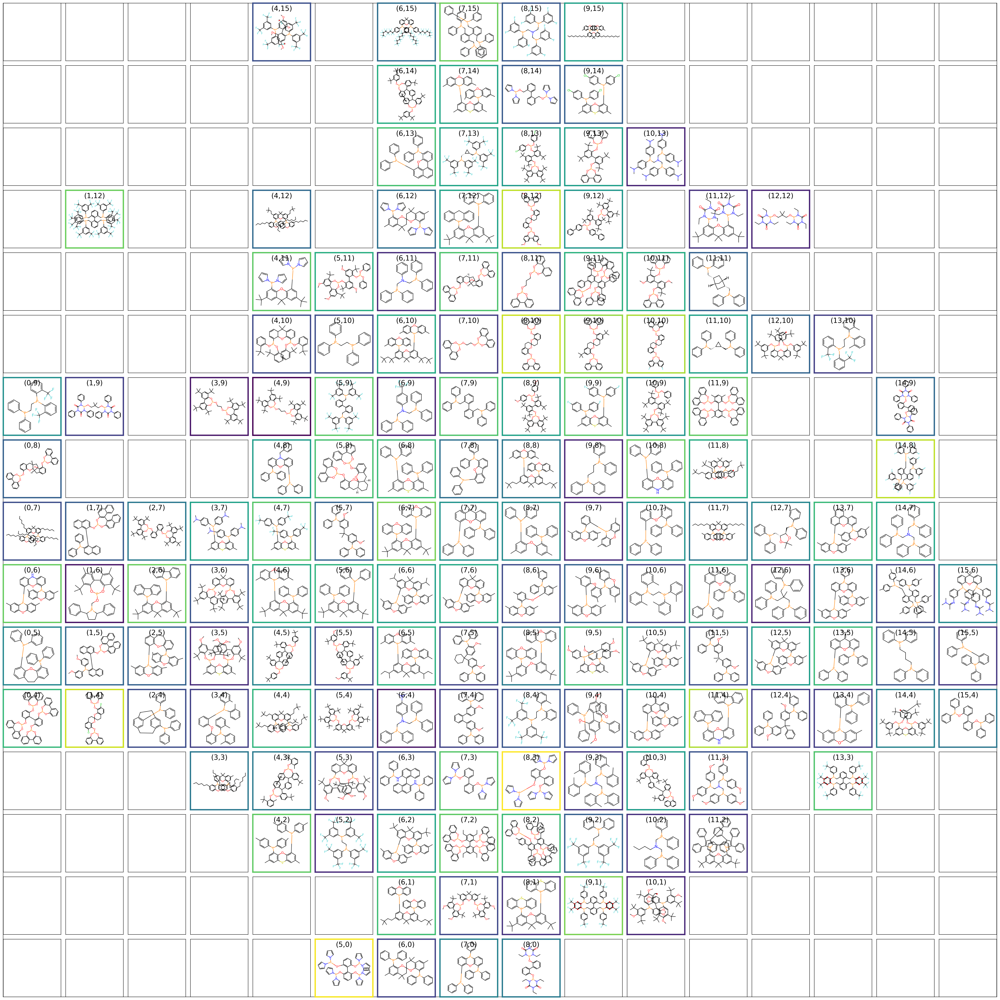

In [196]:
chem_grid(poses[0], 4, preds, u_smiles, cmap=sequential_cmap(torch.min(preds), torch.max(preds)))